
## Imports 

In [6]:
import pandas as pd
import xgboost 
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from pathlib import Path
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import plot_partial_dependence
from fastai.tabular.all import *
import scipy.cluster.hierarchy as hc

pd.options.display.max_columns = 70
pd.options.mode.chained_assignment = None

In [4]:
project_root = Path('.')

In [5]:
train_data = pd.read_csv(project_root/'Data'/'trainval.csv', low_memory=False, parse_dates=[1])
test = pd.read_csv(project_root/'Data'/'test_submission.csv', low_memory=False, parse_dates=[3])

## Time-Based Validation Split

In [4]:
def create_time_splits(df):
    num_days = 6*7
    stores = df['Store'].unique()
    valid_idx = []
    for store in stores:        
        valid_selection = df[df.Store == store].sort_values('Date')[-num_days:]
        valid_idx.extend(list(valid_selection.index))
    train_idx = list(set(df.index) - set(valid_idx))
    return (train_idx, valid_idx)

In [5]:
splits = create_time_splits(train_data)
len(splits[0]), len(splits[1])

(797508, 46830)

In [6]:
cont, cat = cont_cat_split(train_data.drop(['Sales', 'LogSales'], axis = 1))
cont,cat

(['CompetitionDistance', 'compOpenMonths', 'promoOpenMonths'],
 ['Store',
  'Date',
  'Week',
  'Promo',
  'StateHoliday',
  'SchoolHoliday',
  'StoreType',
  'Assortment',
  'CompetitionOpenSinceMonth',
  'CompetitionOpenSinceYear',
  'Promo2',
  'Promo2SinceWeek',
  'Promo2SinceYear',
  'PromoInterval',
  'Year',
  'Month',
  'Day',
  'Dayofweek',
  'Dayofyear',
  'Is_month_end',
  'Is_month_start',
  'Is_quarter_end',
  'Is_quarter_start',
  'Is_year_end',
  'Is_year_start',
  'MonthInPromoInt',
  'DistBin'])

In [127]:
# convert to category
train_data[cat] = train_data[cat].astype('category')
test[cat] = test[cat].astype('category')

In [128]:
X_train, xval = train_data.drop(['Sales', 'LogSales', 'Date'], axis = 1).iloc[splits[0], :], train_data.drop(['Sales', 'LogSales', 'Date'], axis = 1).iloc[splits[1], :]
y_train, yval = train_data.loc[splits[0],'LogSales'], train_data.loc[splits[1],'LogSales']

X_train.shape, X_val.shape, y_train.shape, y_val.shape

((797508, 29), (46830, 29), (797508,), (46830,))

## Metrics

In [146]:
# metrics
def rmspe(y, yhat):
    return np.sqrt(np.mean((yhat/y-1) ** 2))
def eval_rmspe(m, x,y):
    return rmspe(m.predict(x), y)    
def eval_rmspe_exp(m, x,y):
    return rmspe(np.exp(m.predict(x)), np.exp(y))    

## Random Forest

In [147]:
def train_rf_model(xs, y, n_estimators = 50, max_samples=200000,
       max_features=0.5, min_samples_leaf = 30, **kwargs):
    return RandomForestRegressor(n_jobs=-1, n_estimators=n_estimators,
        max_samples=max_samples, max_features=max_features,
        min_samples_leaf=min_samples_leaf, oob_score=True).fit(xs, y)

In [148]:
m = train_rf_model(X_train, y_train, n_estimators = 200, min_samples_leaf = 5, min_samples_split = 2)

In [149]:
eval_rmspe_exp(m, X_train, y_train), eval_rmspe_exp(m, X_val, y_val)

(0.12795692735478809, 0.1330034242909218)

<b> Feature Importance Analysis

In [150]:
def get_rf_importance(m,  df):
    return pd.DataFrame({'cols': df.columns, 'imp': m.feature_importances_}).sort_values('imp', ascending = False)
def plot_fi(fi):
    return fi.plot('cols', 'imp', 'barh', figsize = (12,7))

In [151]:
fi = get_rf_importance(m, X_train)
fi

,cols,imp
7,CompetitionDistance,1.848888e-01
2,Promo,1.625806e-01
0,Store,1.448985e-01
17,Dayofweek,7.106360e-02
8,CompetitionOpenSinceMonth,6.417156e-02
9,CompetitionOpenSinceYear,6.047440e-02
26,compOpenMonths,4.237547e-02
5,StoreType,3.970194e-02
11,Promo2SinceWeek,3.149327e-02
12,Promo2SinceYear,3.126256e-02


<AxesSubplot:ylabel='cols'>

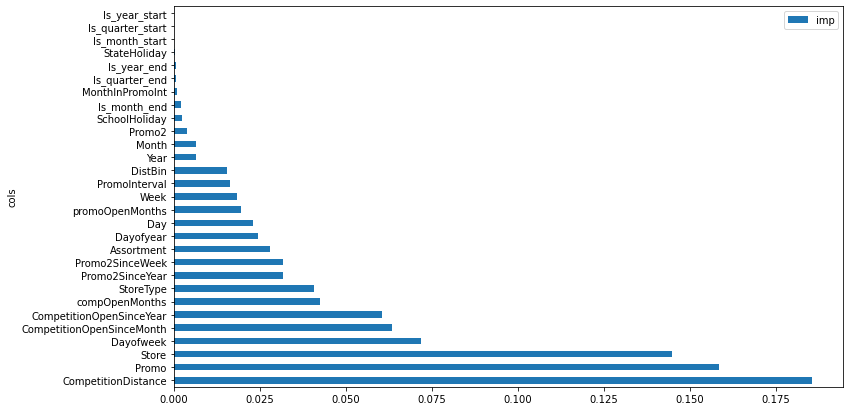

In [143]:
plot_fi(fi)

<b> Drop unimportant features

In [152]:
thresh = 5e-3
imp_features = fi['cols'][fi.imp>thresh]
xtrain_imp, xval_imp = X_train[imp_features], X_val[imp_features]

In [153]:
m_imp = train_rf_model(xtrain_imp, y_train, n_estimators = 200, min_samples_leaf = 5, min_samples_split = 2)

In [154]:
eval_rmspe_exp(m_imp, xtrain_imp, y_train), eval_rmspe_exp(m_imp, xval_imp, y_val)

(0.12899419107664586, 0.13543707134771343)

<AxesSubplot:ylabel='cols'>

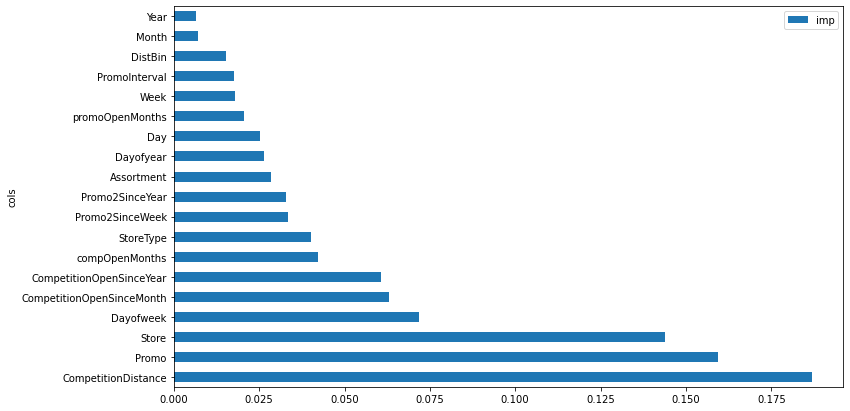

In [155]:
fi = get_rf_importance(m_imp, xtrain_imp)
plot_fi(fi)

<b> Feature Selection based on Column Similarity

In [134]:
# redundant features
def cluster_columns(df, figsize=(10,6), font_size=12):
    corr = np.round(scipy.stats.spearmanr(df).correlation, 4)
    corr_condensed = hc.distance.squareform(1-corr)
    z = hc.linkage(corr_condensed, method='average')
    fig = plt.figure(figsize=figsize)
    hc.dendrogram(z, labels=df.columns, orientation='left', leaf_font_size=font_size)
    plt.show()

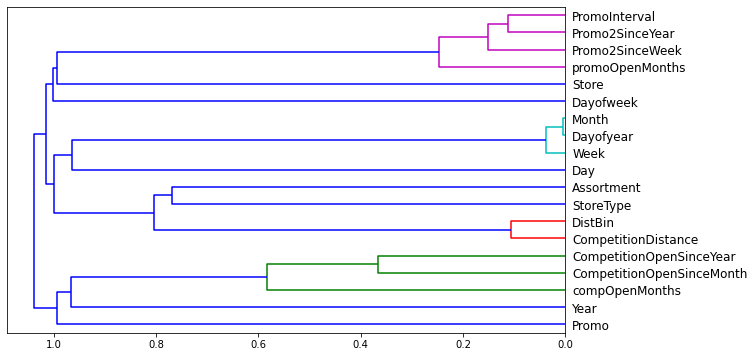

In [154]:
cluster_columns(xtrain_imp)

In [12]:
similar = [ 'DistBin', 'CompetitionDistance', 'Month', 'Dayofyear', 'Week', 'PromoInterval', 'Promo2SinceYear']

def get_oob(xs, ys):
    return train_rf_model(xs, ys).oob_score_

In [161]:
# trying to drop 
print(f'Original OOB: {get_oob(xtrain_imp, y_train)}')
for d in similar:
    print(f'Dropping: {d}..OOB: {get_oob(xtrain_imp.drop(d, axis = 1), y_train)}')

Original OOB: 0.8348378031312244
Dropping: DistBin..OOB: 0.830595747995524
Dropping: CompetitionDistance..OOB: 0.8076180879151601
Dropping: Month..OOB: 0.8390381018779096
Dropping: Dayofyear..OOB: 0.8352248391746255
Dropping: Week..OOB: 0.8382431709318144
Dropping: PromoInterval..OOB: 0.8358994070381136
Dropping: Promo2SinceYear..OOB: 0.8368182115376088


In [156]:
# dropping multiple - improved R squared
to_drop = ['Month', 'Dayofyear', 'Promo2SinceYear']
get_oob(xtrain_imp.drop(to_drop, axis = 1), y_train)

0.834938364570296

In [157]:
xtrain_filt = xtrain_imp.drop(to_drop, axis = 1)
xval_filt = xval_imp.drop(to_drop, axis = 1)

In [158]:
m_filt = train_rf_model(xtrain_filt, y_train, n_estimators = 300, min_samples_leaf = 5, min_samples_split = 2)

In [159]:
eval_rmspe_exp(m_filt, xtrain_filt, y_train), eval_rmspe_exp(m_filt, xval_filt, y_val)

(0.13014498138988292, 0.13512855428387074)

<AxesSubplot:ylabel='cols'>

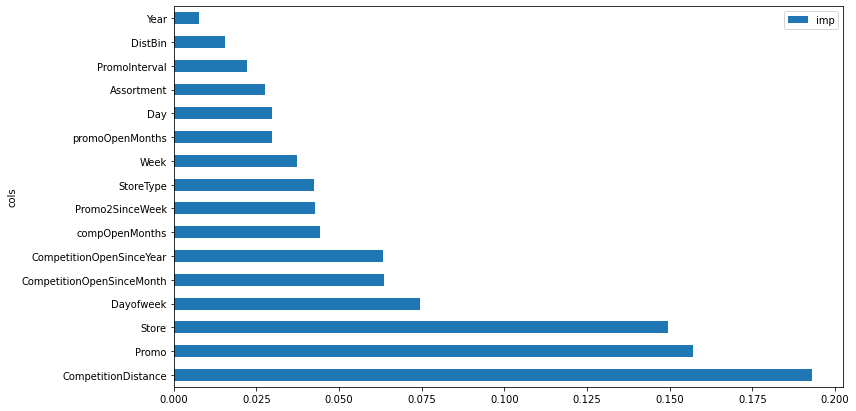

In [139]:
fi = get_rf_importance(m_filt, xtrain_filt)
plot_fi(fi)

In [160]:
# saving
(project_root/'Model'/'rf-val.pkl').save(m_filt)
(project_root/'Model'/'features-rf.pkl').save(list(xtrain_filt.columns))

################

In [175]:
# more feature deletion
similar = ['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 
           'compOpenMonths','promoOpenMonths', 'Promo2SinceWeek', 'DistBin', 'CompetitionDistance']

# trying to drop 
print(f'Original OOB: {get_oob(xtrain_filt, y_train)}')
for d in similar:
    print(f'Dropping: {d}..OOB: {get_oob(xtrain_filt.drop(d, axis = 1), y_train)}')

Original OOB: 0.8349436621415354
Dropping: CompetitionOpenSinceMonth..OOB: 0.820296865159206
Dropping: CompetitionOpenSinceYear..OOB: 0.8280620568523416
Dropping: compOpenMonths..OOB: 0.8277718721194516
Dropping: promoOpenMonths..OOB: 0.8277722611878949
Dropping: Promo2SinceWeek..OOB: 0.8240184836045776
Dropping: DistBin..OOB: 0.827475099363181
Dropping: CompetitionDistance..OOB: 0.7950467485956972


In [176]:
to_drop2 = ['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'DistBin']
get_oob(xtrain_filt.drop(to_drop2, axis = 1), y_train)

0.7936886658488875

Score got worse so let's keep them

<b> Partial Dependence Plots

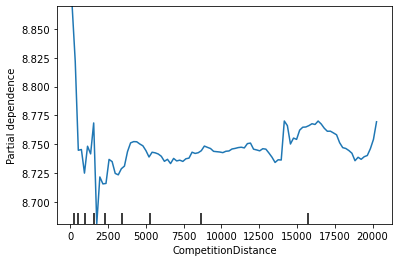

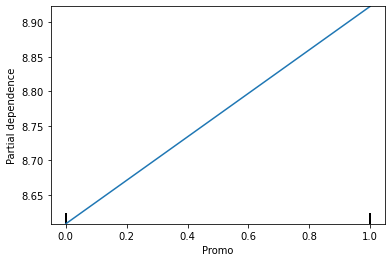

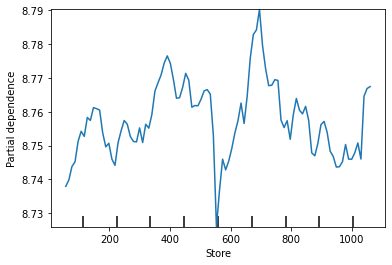

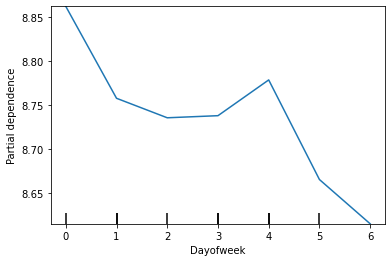

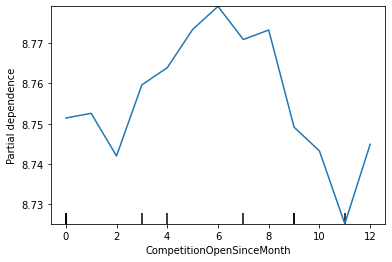

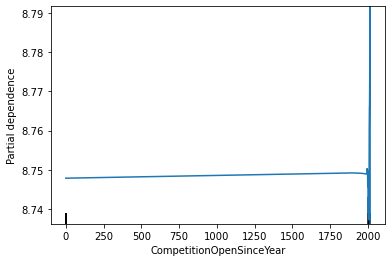

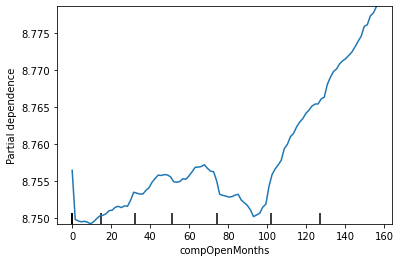

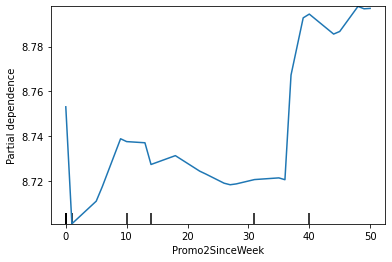

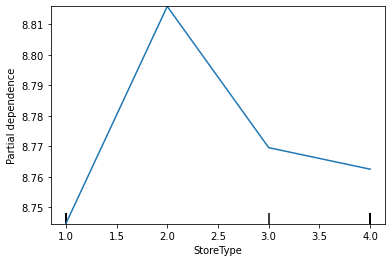

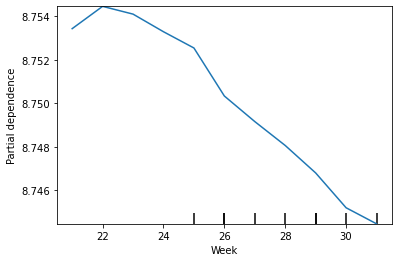

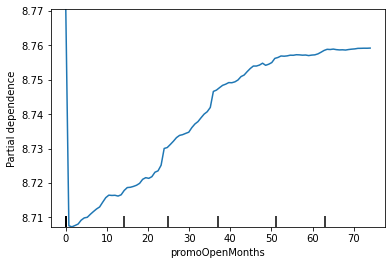

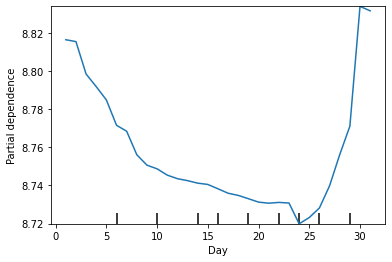

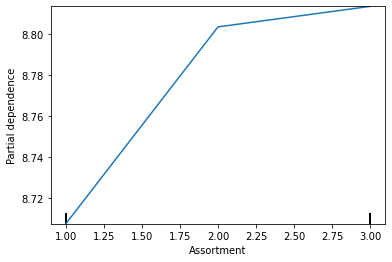

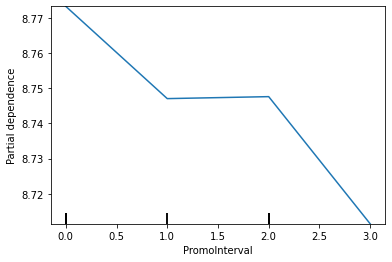

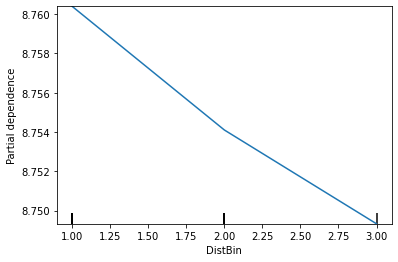

C:\Users\Arpan\Anaconda3\lib\site-packages\sklearn\inspection\_plot\partial_dependence.py:582: UserWarning: Attempting to set identical bottom == top == 8.770142577549464 results in singular transformations; automatically expanding.
  axi.set_ylim(self.pdp_lim[1])


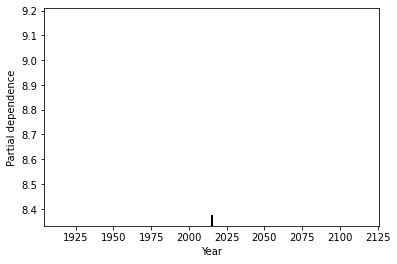

In [183]:
for f in fi.cols:
    plot_partial_dependence(m_filt, xval_filt, [f])
    plt.show()

In [215]:
train_data.groupby('Promo2').agg({'Sales':['mean','std']})

Sales             
               mean          std
Promo2                          
0       7350.818414  3394.049065
1       6558.993542  2724.593057

Promoint's pdp suggests that the sales are highes for stores which do not participate in promo2 (highest at 0) <br>
This is reaffirmed by the mean sales grouped by Promo2

<b> Predictions - only to submit on kaggle

In [141]:
# get predictions
def get_preds(m, xs, features, exp = False):
    ids = xs['Id']
    x = xs.drop('Id', axis = 1)
    x = x[features]    
    preds = m.predict(x)
    if exp:
        preds = np.exp(preds)
    
    return pd.DataFrame(data = {'Id':ids, 'Sales':preds}).sort_values('Id').reset_index(drop = True)

In [142]:
features = xtrain_filt.columns

In [143]:
rf_full_model = train_rf_model(xtrain_filt.append(xval_filt), y_train.append(y_val), 
           n_estimators = 300, min_samples_leaf = 5, min_samples_split = 2)

In [144]:
(project_root/'Model'/'rf-all.pkl').save(rf_full_model)

In [200]:
predictions = get_preds(rf_full_model, test, features, exp = True)
predictions

,Id,Sales
0,1,4580.891655
1,2,7823.750084
2,3,9329.253562
3,4,7036.626147
4,5,7550.675285
...,...,...
41083,41084,2990.262156
41084,41085,7526.469032
41085,41086,6067.956289
41086,41087,21707.912777


In [201]:
predictions.to_csv('rf-sub.csv', index = False) #0.12177

## XGBOOST

In [14]:
def train_xgb_model(xs, ys, objective = 'reg:squarederror', n_estimators = 200, max_depth = 3, learning_rate = 0.001, 
        booster = 'gbtree', colsample_bytree = 0.5, **kwargs):
    return xgboost.XGBRegressor(objective = objective, 
                         n_estimators = n_estimators, max_depth = max_depth, learning_rate = learning_rate,
                        booster = booster, colsample_bytree = colsample_bytree, n_jobs = -1).fit(xs, ys)

In [ ]:
# convert categories to int
categories = [c for c in X_train.columns if X_train[c].dtypes!=np.float64]
xtrain_xgb, xval_xgb = X_train.copy(), X_val.copy()
xtrain_xgb[categories] = xtrain_xgb[categories].astype(np.int64)
xval_xgb[categories] = xval_xgb[categories].astype(np.int64)

<b> Hyperparameter Tuning

In [252]:
mxgb = train_xgb_model(xtrain_xgb, y_train, n_estimators = 300, max_depth = 10, learning_rate = 0.1)

In [253]:
eval_rmspe_exp(mxgb, xtrain_xgb, y_train), eval_rmspe_exp(mxgb, xval_xgb, y_val)

(0.0949529443935043, 0.12748615526321716)

In [256]:
mxgb = train_xgb_model(xtrain_xgb, y_train, n_estimators = 300, max_depth = 10, learning_rate = 0.1, subsample = 0.4)

In [257]:
eval_rmspe_exp(mxgb, xtrain_xgb, y_train), eval_rmspe_exp(mxgb, xval_xgb, y_val)

(0.0949529443935043, 0.12748615526321716)

In [258]:
mxgb = train_xgb_model(xtrain_xgb, y_train, n_estimators = 500, max_depth = 10, learning_rate = 0.1, subsample = 0.4)

In [259]:
eval_rmspe_exp(mxgb, xtrain_xgb, y_train), eval_rmspe_exp(mxgb, xval_xgb, y_val)

(0.0833539301790422, 0.12412491258333541)

In [262]:
mxgb = train_xgb_model(xtrain_xgb, y_train, n_estimators = 500, max_depth = 8, learning_rate = 0.1, subsample = 0.4)

In [263]:
eval_rmspe_exp(mxgb, xtrain_xgb, y_train), eval_rmspe_exp(mxgb, xval_xgb, y_val)

(0.10502749213106037, 0.1289008026276894)

In [33]:
mxgb = train_xgb_model(xtrain_xgb, y_train, n_estimators = 500, max_depth = 10, learning_rate = 0.08, subsample = 0.4, reg_lambda = 0.01)

In [34]:
eval_rmspe_exp(mxgb, xtrain_xgb, y_train), eval_rmspe_exp(mxgb, xval_xgb, y_val)

(0.0882100010391496, 0.1227059074292185)

<b> Feature Importance Analysis

In [15]:
def get_xgb_importance(m,  df):
    return pd.DataFrame({'cols': df.columns, 'imp': m.feature_importances_}).sort_values('imp', ascending = False)

In [35]:
fixgb = get_xgb_importance(mxgb, xtrain_xgb)
fixgb

,cols,imp
2,Promo,0.229317
7,CompetitionDistance,0.081598
12,Promo2SinceYear,0.078141
0,Store,0.064825
5,StoreType,0.063175
6,Assortment,0.061051
8,CompetitionOpenSinceMonth,0.052248
9,CompetitionOpenSinceYear,0.050589
10,Promo2,0.043701
13,PromoInterval,0.042174


In [36]:
thresh = 0.007
features_imp = fixgb.cols[fixgb.imp > thresh]
xtrain_xgb_imp, xval_xgb_imp = xtrain_xgb[features_imp], xval_xgb[features_imp]

In [278]:
mxgb_imp = train_xgb_model(xtrain_xgb_imp, y_train, n_estimators = 500, max_depth = 10, learning_rate = 0.08, subsample = 0.4, reg_lambda = 0.01)

In [279]:
eval_rmspe_exp(mxgb_imp, xtrain_xgb_imp, y_train), eval_rmspe_exp(mxgb_imp, xval_xgb_imp, y_val)

(0.08953070108667278, 0.12336975254941208)

In [284]:
mxgb_imp = train_xgb_model(xtrain_xgb_imp, y_train, n_estimators = 600, max_depth = 10, learning_rate = 0.08, subsample = 0.5, reg_lambda = 0.02)

In [285]:
eval_rmspe_exp(mxgb_imp, xtrain_xgb_imp, y_train), eval_rmspe_exp(mxgb_imp, xval_xgb_imp, y_val)

(0.085409895666388, 0.12185030852675743)

<b> Dropping features - based on rf oob score

In [37]:
to_drop = ['Dayofyear', 'Promo2SinceYear']
xtrain_xgb_filt, xval_xgb_filt = xtrain_xgb_imp.drop(to_drop, axis = 1), xval_xgb_imp.drop(to_drop, axis = 1)

In [289]:
mxgb_filt = train_xgb_model(xtrain_xgb_filt, y_train, n_estimators = 600, max_depth = 10, learning_rate = 0.08, subsample = 0.5, reg_lambda = 0.02)

In [290]:
eval_rmspe_exp(mxgb_filt, xtrain_xgb_filt, y_train), eval_rmspe_exp(mxgb_filt, xval_xgb_filt, y_val)

(0.08666830243614607, 0.12241831894478647)

In [38]:
mxgb_filt = train_xgb_model(xtrain_xgb_filt, y_train, n_estimators = 800, max_depth = 10, learning_rate = 0.06, subsample = 0.5, reg_lambda = 0.02)

In [39]:
eval_rmspe_exp(mxgb_filt, xtrain_xgb_filt, y_train), eval_rmspe_exp(mxgb_filt, xval_xgb_filt, y_val)

(0.08746014543255834, 0.12110308957437994)

In [40]:
# saving model
(project_root/'Model'/'xgb-val.pkl').save(mxgb_filt)
(project_root/'Model'/'feature-xgb.pkl').save(list(xtrain_xgb_filt.columns))

############

In [296]:
mxgb_filt = train_xgb_model(xtrain_xgb_filt, y_train, n_estimators = 800, max_depth = 12, learning_rate = 0.03, subsample = 0.6, reg_lambda = 0.02)

In [297]:
eval_rmspe_exp(mxgb_filt, xtrain_xgb_filt, y_train), eval_rmspe_exp(mxgb_filt, xval_xgb_filt, y_val)

(0.08452684145961607, 0.12184889558613156)

<b> Predictions - For Kaggle

In [299]:
featuresxgb = xtrain_xgb_filt.columns

In [41]:
xgb_full_model = train_xgb_model(xtrain_xgb_filt.append(xval_xgb_filt), y_train.append(y_val), n_estimators = 800, max_depth = 10, learning_rate = 0.06, subsample = 0.5, reg_lambda = 0.02)

In [42]:
(project_root/'Model'/'xgb-full.pkl').save(xgb_full_model)

In [301]:
testxgb = test.copy()
testxgb[categories] = testxgb[categories].astype(np.int64)

In [303]:
predictions = get_preds(xgb_full_model, testxgb, featuresxgb, exp = True)
predictions

,Id,Sales
0,1,4112.878418
1,2,7473.230469
2,3,9113.497070
3,4,6848.874023
4,5,6831.229004
...,...,...
41083,41084,2637.848633
41084,41085,7781.312500
41085,41086,6486.937988
41086,41087,23832.169922


In [304]:
predictions.to_csv('xgb-preds.csv', index = False) # 0.11213

## Neural Networks

In [69]:
# cont cat splits
d = ['Sales', 'Date']
cont, cat = cont_cat_split(train_data.drop(d, axis = 1), dep_var = 'LogSales', max_card = 9000)

In [70]:
# convert to Tabular Pandas
procs = [Categorify, Normalize]
to = TabularPandas(train_data.drop(d, axis = 1), y_names = 'LogSales', cont_names=cont, cat_names = cat, procs = procs, splits=splits)

In [323]:
# train
to.train.items.head()

,Store,Week,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,LogSales,Year,Month,Day,Dayofweek,Dayofyear,Is_month_end,Is_month_start,Is_quarter_end,Is_quarter_start,Is_year_end,Is_year_start,MonthInPromoInt,compOpenMonths,promoOpenMonths,DistBin
42,1,24,1,1,1,3,1,-0.534959,10,17,1,1,1,1,8.214736,3,6,12,5,163,1,1,1,1,1,1,1,0.750491,-0.698698,1
43,1,24,1,1,1,3,1,-0.534959,10,17,1,1,1,1,8.196161,3,6,11,4,162,1,1,1,1,1,1,1,0.750491,-0.698698,1
44,1,24,1,1,1,3,1,-0.534959,10,17,1,1,1,1,8.186186,3,6,10,3,161,1,1,1,1,1,1,1,0.750491,-0.698698,1
45,1,24,1,1,1,3,1,-0.534959,10,17,1,1,1,1,8.319230,3,6,9,2,160,1,1,1,1,1,1,1,0.750491,-0.698698,1
46,1,24,1,1,1,3,1,-0.534959,10,17,1,1,1,1,8.311644,3,6,8,1,159,1,1,1,1,1,1,1,0.750491,-0.698698,1


In [324]:
# valid
to.valid.items.head()

,Store,Week,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,LogSales,Year,Month,Day,Dayofweek,Dayofyear,Is_month_end,Is_month_start,Is_quarter_end,Is_quarter_start,Is_year_end,Is_year_start,MonthInPromoInt,compOpenMonths,promoOpenMonths,DistBin
41,1,24,1,1,1,3,1,-0.534959,10,17,1,1,1,1,8.356085,3,6,13,6,164,1,1,1,1,1,1,1,0.750491,-0.698698,1
40,1,25,2,1,1,3,1,-0.534959,10,17,1,1,1,1,8.615770,3,6,15,1,166,1,1,1,1,1,1,1,0.750491,-0.698698,1
39,1,25,2,1,1,3,1,-0.534959,10,17,1,1,1,1,8.487146,3,6,16,2,167,1,1,1,1,1,1,1,0.750491,-0.698698,1
38,1,25,2,1,1,3,1,-0.534959,10,17,1,1,1,1,8.294049,3,6,17,3,168,1,1,1,1,1,1,1,0.750491,-0.698698,1
37,1,25,2,1,1,3,1,-0.534959,10,17,1,1,1,1,8.443546,3,6,18,4,169,1,1,1,1,1,1,1,0.750491,-0.698698,1


In [18]:
# metrics
def nn_rmspe_exp(preds,targs):return rmspe(np.exp(targs.cpu().detach().numpy()), np.exp(preds.cpu().detach().numpy()))

In [328]:
# determining y range values
to.train.y.min(), to.train.y.max()

(3.828641414642334, 10.564163208007812)

In [19]:
# dataloader and learn object
def get_learner(to, bs, layers = [500, 250], **kwargs):    
    dls = to.dataloaders(bs)
    return  tabular_learner(dls, layers = layers, 
                            loss_func = F.mse_loss, 
                            metrics = [nn_rmspe_exp], n_out = 1,
                            y_range = (3., 11.))

In [334]:
learn = get_learner(to, 1024)

SuggestedLRs(lr_min=0.010000000149011612, lr_steep=0.0005754399462603033)

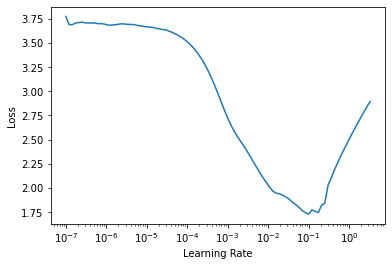

In [335]:
learn.lr_find()

In [336]:
learn.fit_one_cycle(6, 8e-3)

epoch,train_loss,valid_loss,nn_rmspe_exp,time
0,0.019827,0.024092,0.165760,00:22
1,0.012885,0.016320,0.131948,00:21
2,0.010228,0.015055,0.129346,00:22
3,0.008225,0.013456,0.120091,00:21
4,0.006916,0.013355,0.122816,00:21
5,0.006240,0.012983,0.120258,00:22


In [340]:
learn = get_learner(to, 1024, config = tabular_config(embed_p = 0.2))

SuggestedLRs(lr_min=0.03019951581954956, lr_steep=0.0008317637839354575)

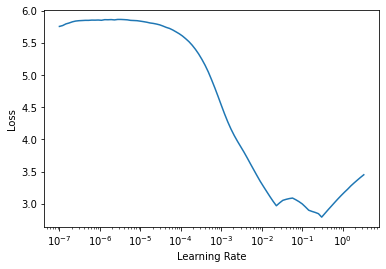

In [341]:
learn.lr_find()

In [342]:
learn.fit_one_cycle(10, 1e-2)

epoch,train_loss,valid_loss,nn_rmspe_exp,time
0,0.018515,0.026911,0.177912,00:22
1,0.014815,0.018488,0.143137,00:22
2,0.011559,0.017882,0.146957,00:22
3,0.009640,0.014907,0.126652,00:22
4,0.008547,0.014463,0.128349,00:22
5,0.007807,0.014902,0.122402,00:22
6,0.007036,0.014450,0.122869,00:27
7,0.006447,0.014224,0.123671,00:25
8,0.005905,0.014492,0.125458,00:24
9,0.005678,0.014567,0.126182,00:24


In [343]:
# wd
learn = get_learner(to, 1024)

In [344]:
learn.fit_one_cycle(10, 8e-3, wd = 0.03)

epoch,train_loss,valid_loss,nn_rmspe_exp,time
0,0.017898,0.023271,0.163555,00:25
1,0.015199,0.022404,0.140572,00:29
2,0.011618,0.017297,0.128340,00:28
3,0.010094,0.017419,0.130371,00:29
4,0.008731,0.014331,0.123998,00:28
5,0.007936,0.014559,0.124084,00:29
6,0.006887,0.014568,0.124232,00:29
7,0.006495,0.014313,0.122588,00:29
8,0.005860,0.014015,0.120045,00:28
9,0.005371,0.014129,0.121046,00:23


In [350]:
# wd
learn = get_learner(to, 1024, layers = [600, 300])

In [351]:
learn.fit_one_cycle(14, 1e-2, wd = 0.06)

epoch,train_loss,valid_loss,nn_rmspe_exp,time
0,0.017794,0.024321,0.170650,00:22
1,0.015604,0.020037,0.144523,00:22
2,0.012821,0.017708,0.142959,00:22
3,0.011166,0.016800,0.141109,00:22
4,0.010648,0.016234,0.130099,00:22
5,0.009473,0.015633,0.122887,00:22
6,0.009200,0.014864,0.126651,00:22
7,0.008769,0.013212,0.117264,00:23
8,0.007705,0.013918,0.120470,00:22
9,0.007604,0.013002,0.120065,00:21


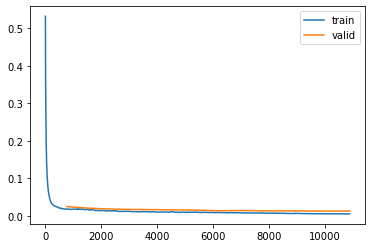

In [355]:
learn.recorder.plot_loss()

In [356]:
# save
learn.save(project_root/'Model'/'nn-600-300-wd06')

Path('models/nn-600-300-wd06.pth')

In [409]:
learn = get_learner(to, 1024, layers = [600, 300], config = tabular_config(embed_p = 0.2), wd = 0.03)

SuggestedLRs(lr_min=0.006918309628963471, lr_steep=0.0004786300996784121)

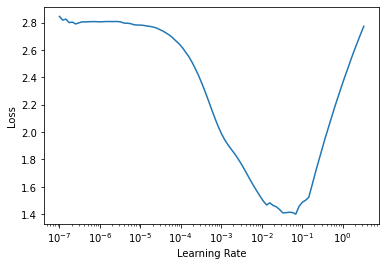

In [410]:
learn.lr_find()

In [411]:
learn.fit_one_cycle(10, 8e-3)

epoch,train_loss,valid_loss,nn_rmspe_exp,time
0,0.018053,0.021410,0.154712,00:22
1,0.015488,0.016942,0.136001,00:22
2,0.011353,0.019755,0.154864,00:22
3,0.010052,0.018277,0.148323,00:23
4,0.008739,0.014542,0.124438,00:23
5,0.007600,0.014389,0.127495,00:23
6,0.006650,0.014282,0.124042,00:23
7,0.006241,0.014424,0.129015,00:23
8,0.005595,0.013893,0.124230,00:22
9,0.005174,0.013887,0.124292,00:23


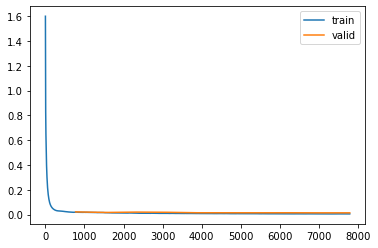

In [412]:
learn.recorder.plot_loss()

<b> Predictions

In [413]:
# training on full dataset
procs = [Categorify, Normalize]
to_full = TabularPandas(train_data.drop(d, axis = 1), y_names = 'LogSales', cont_names=cont, cat_names = cat, procs = procs)

In [499]:
learn = get_learner(to_full, 1024, layers = [600, 300],  config = tabular_config(embed_p = 0.2), wd = 0.03)

In [415]:
learn.fit_one_cycle(10, 8e-3)

epoch,train_loss,valid_loss,nn_rmspe_exp,time
0,0.019270,None,None,00:23
1,0.015276,None,None,00:23
2,0.011429,None,None,00:23
3,0.010288,None,None,00:23
4,0.008525,None,None,00:24
5,0.007692,None,None,00:24
6,0.007183,None,None,00:24
7,0.006399,None,None,00:23
8,0.005860,None,None,00:23
9,0.005424,None,None,00:23


C:\Users\Arpan\Anaconda3\lib\site-packages\fastprogress\fastprogress.py:74: UserWarning: Your generator is empty.
  warn("Your generator is empty.")


In [416]:
# # save
# learn.save(path/'Model'/'nn_full_600-300-wd06')

Path('models/nn_full_600-300-wd06.pth')

In [516]:
learn.load(project_root/'Model'/'nn_full_600-300-wd06')

In [ ]:
# getting predictions
preds = [torch.exp(learn.predict(test.iloc[i])[1]).item() for i in range(len(test))]

In [584]:
prediction = pd.DataFrame({'Id': test.Id, 'Sales': preds}).sort_values('Id').reset_index(drop = True)
prediction # 0.112

,Id,Sales
0,1,4344.852539
1,2,7798.502930
2,3,9321.622070
3,4,8691.259766
4,5,8640.227539
...,...,...
41083,41084,3350.622314
41084,41085,8009.229980
41085,41086,6643.736328
41086,41087,24444.541016


<AxesSubplot:>

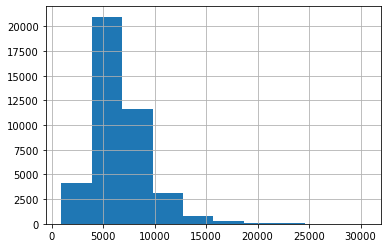

In [585]:
prediction.Sales.hist()

In [586]:
prediction.to_csv('nn-ee.csv', index = False)